# 03 · O prazo prometido: pontualidade x prazo

O app não mostra a mediana. Ele mostra um **prazo**: "chega em até X minutos". Se o prazo for curto demais, a entrega atrasa e o cliente reclama. Se for longo demais, o cliente desiste de pedir. O que importa pro negócio:

- **pontualidade:** % de entregas que chegam dentro do prazo prometido (a meta aqui é 90%)
- **prazo médio prometido:** quanto o app promete em média (menor = app mais atraente)
- **atraso > 10 min:** os atrasos que mais irritam

### Métodos
1. **Previsão pontual + margem fixa:** soma a mesma margem a todo pedido. A margem é calibrada nos dados de calibração (09–11/02) pra atingir a meta.
2. **LightGBM quantílico + conformal:** um modelo treinado direto no quantil da meta (ex.: 0,9). A margem é ajustada por **conformal prediction**: uma correção calculada na calibração que garante a meta em dados parecidos com os de calibração. A margem **varia por pedido**: é maior quando o modelo está mais incerto.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

# paleta categórica validada (daltonismo) + estilo discreto
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3b3b38",
    "xtick.color": "#5c5c58", "ytick.color": "#5c5c58",
    "lines.linewidth": 2, "lines.markersize": 7, "figure.dpi": 110,
})

In [2]:
from eta import load, build
from eta.avaliacao import treinar_tudo, prazos, tabela, curva_tradeoff, metricas_prazo, ALVOS

df = load()
X = build(df, df.loc[df["periodo"] == "treino", "minutos"].mean())
y = df["minutos"].to_numpy()
P = {p: (df["periodo"] == p).to_numpy() for p in ["treino", "validacao", "calibracao", "teste"]}
pontuais, quantis = treinar_tudo(X, y, P)   # ~30 s
te = P["teste"]

## 1. Metas de 80% a 95% (margens calibradas em 09–11/02, resultado no teste)

In [3]:
tab = tabela(prazos(pontuais, quantis, X, y, P), y[te])
ordem = ["Mediana global + margem fixa", "Regra (envio + deslocamento + preparo mediano) + margem fixa",
         "LightGBM (mediana) + margem fixa", "LightGBM quantílico + conformal"]
for col, fmt in [("pontualidade", 100), ("prazo_medio", 1), ("atraso_10min", 100)]:
    print(f"\n{col}" + (" (%)" if fmt == 100 else " (min)"))
    print((tab.pivot(index="metodo", columns="alvo", values=col).loc[ordem] * fmt).round(1).to_string())


pontualidade (%)
alvo                                                          0.80  0.85  0.90  0.95
metodo                                                                              
Mediana global + margem fixa                                  73.3  78.8  84.8  91.4
Regra (envio + deslocamento + preparo mediano) + margem fixa  73.2  78.9  84.7  91.4
LightGBM (mediana) + margem fixa                              75.7  81.3  87.2  93.1
LightGBM quantílico + conformal                               75.6  81.5  86.8  92.8

prazo_medio (min)
alvo                                                          0.80  0.85  0.90  0.95
metodo                                                                              
Mediana global + margem fixa                                  56.7  60.5  65.5  74.1
Regra (envio + deslocamento + preparo mediano) + margem fixa  56.2  59.8  64.8  73.2
LightGBM (mediana) + margem fixa                              55.6  58.7  63.0  70.3
LightGBM quantílico + confor

Os dois métodos com LightGBM prometem **de 1 a 3 minutos a menos** que a regra e ainda assim chegam no prazo com mais frequência. Na meta de 90%, eles também cortam o atraso de mais de 10 minutos de ~7,7% pra ~5,4%. Todos ficam um pouco abaixo da meta no teste por causa da semana atípica. Isso é tratado na seção 4.

## 2. Fronteira: quem promete menos pra mesma pontualidade

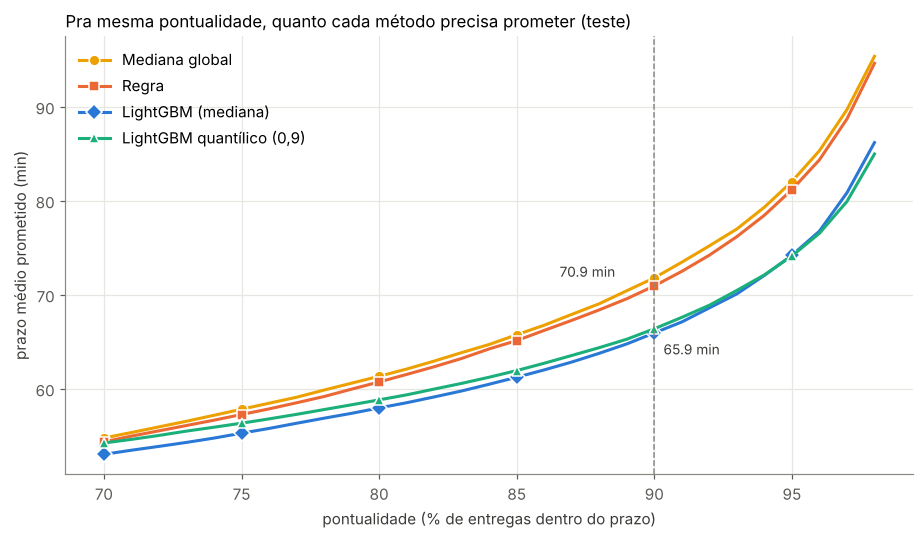

{'Mediana global': 71.8, 'Regra (envio + deslocamento + preparo mediano)': 70.9, 'LightGBM (mediana)': 65.9, 'LightGBM quantílico (0,9)': 66.4}


In [4]:
curvas = {m.nome: curva_tradeoff(m.predict(X[te]), y[te]) for m in pontuais}
curvas["LightGBM quantílico (0,9)"] = curva_tradeoff(quantis[0.9].predict(X[te]), y[te])
fig, ax = plt.subplots(figsize=(8.5, 5))
estilos = [("Mediana global", CORES[3], "o"), ("Regra (envio + deslocamento + preparo mediano)", CORES[1], "s"),
           ("LightGBM (mediana)", CORES[0], "D"), ("LightGBM quantílico (0,9)", CORES[2], "^")]
for nome, cor, mk in estilos:
    c = curvas[nome]
    ax.plot(c["pontualidade"] * 100, c["prazo_medio"], color=cor, label=nome.replace(" (envio + deslocamento + preparo mediano)", ""),
            marker=mk, markevery=5, markeredgecolor="white")
ax.axvline(90, color="#8a8a85", lw=1, ls="--")
r90 = {n: float(np.interp(0.9, c["pontualidade"], c["prazo_medio"])) for n, c in curvas.items()}
ax.annotate(f"{r90['Regra (envio + deslocamento + preparo mediano)']:.1f} min", (90, r90["Regra (envio + deslocamento + preparo mediano)"]),
            xytext=(-62, 6), textcoords="offset points", fontsize=9, color="#3b3b38")
ax.annotate(f"{r90['LightGBM (mediana)']:.1f} min", (90, r90["LightGBM (mediana)"]), xytext=(6, -14), textcoords="offset points", fontsize=9, color="#3b3b38")
ax.set_xlabel("pontualidade (% de entregas dentro do prazo)"); ax.set_ylabel("prazo médio prometido (min)")
ax.set_title("Pra mesma pontualidade, quanto cada método precisa prometer (teste)", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig("../results/fronteira_prazo.png", dpi=150); plt.show()
print({k: round(v, 1) for k, v in r90.items()})

Pra entregar 90% no prazo, a regra precisa prometer **~71 min** em média e o LightGBM **~66 min**: são **5 minutos a menos** no app, com a mesma pontualidade.

## 3. Onde cada método atrasa (meta de 90%)

A média esconde um problema: com margem fixa, quem paga a conta são os pedidos longos.

In [5]:
pr = prazos(pontuais, quantis, X, y, P, alvos=(0.9,))
d = df[te].copy()
nomes = {"Regra (envio + deslocamento + preparo mediano) + margem fixa": "Regra + margem fixa",
         "LightGBM (mediana) + margem fixa": "LightGBM mediana + margem fixa",
         "LightGBM quantílico + conformal": "LightGBM quantílico + conformal"}
for k, v in nomes.items():
    d[v] = pr[(k, 0.9)]
d["faixa"] = pd.qcut(pontuais[2].predict(X[te]), 5, labels=["muito rápido", "rápido", "médio", "lento", "muito lento"])
por_faixa = d.groupby("faixa", observed=True).apply(lambda g: pd.Series({v: (g["minutos"] <= g[v]).mean() * 100 for v in nomes.values()}))
por_mercado = d.groupby("market_id").apply(lambda g: pd.Series({v: (g["minutos"] <= g[v]).mean() * 100 for v in nomes.values()}))
print("Pontualidade (%) por faixa de tempo previsto:"); print(por_faixa.round(1).to_string())
print("\nPontualidade (%) por mercado:"); print(por_mercado.round(1).to_string())
print("\nDiferença entre a melhor e a pior faixa (pontos percentuais):")
print((por_faixa.max() - por_faixa.min()).round(1).to_string())

Pontualidade (%) por faixa de tempo previsto:
              Regra + margem fixa  LightGBM mediana + margem fixa  LightGBM quantílico + conformal
faixa                                                                                             
muito rápido                 97.5                            91.2                             88.1
rápido                       94.1                            88.4                             86.7
médio                        89.9                            87.5                             86.9
lento                        81.4                            85.2                             86.2
muito lento                  60.5                            83.4                             86.4

Pontualidade (%) por mercado:
           Regra + margem fixa  LightGBM mediana + margem fixa  LightGBM quantílico + conformal
market_id                                                                                      
1.0                       75.6        

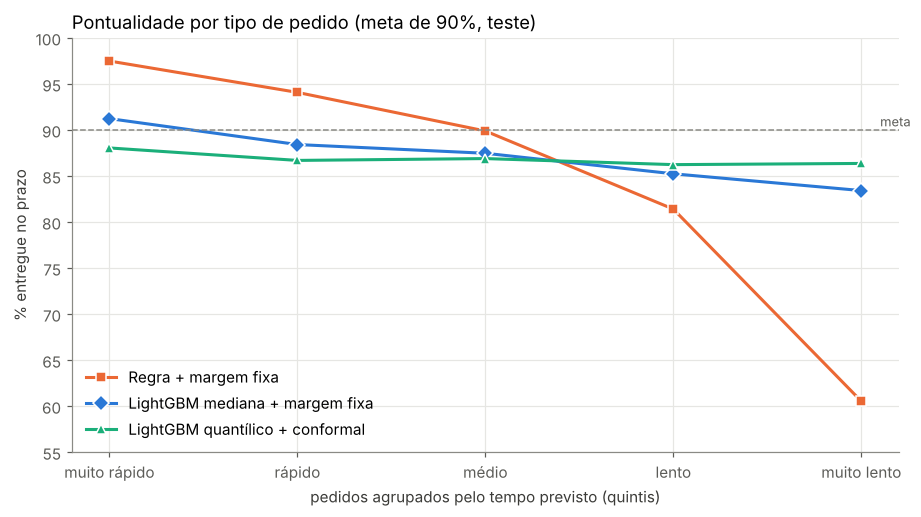

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
x = np.arange(len(por_faixa))
for (nome, cor, mk) in zip(nomes.values(), [CORES[1], CORES[0], CORES[2]], ["s", "D", "^"]):
    ax.plot(x, por_faixa[nome], color=cor, marker=mk, markeredgecolor="white", label=nome)
ax.axhline(90, color="#8a8a85", lw=1, ls="--"); ax.text(4.1, 90.4, "meta", fontsize=8.5, color="#5c5c58")
ax.set_xticks(x, por_faixa.index); ax.set_xlabel("pedidos agrupados pelo tempo previsto (quintis)")
ax.set_ylabel("% entregue no prazo"); ax.set_ylim(55, 100)
ax.set_title("Pontualidade por tipo de pedido (meta de 90%, teste)", loc="left")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.savefig("../results/pontualidade_por_faixa.png", dpi=150); plt.show()

- **Regra + margem fixa:** quase todos os pedidos rápidos chegam no prazo, mas os pedidos longos chegam no prazo só ~60% das vezes. A margem sobra pra um grupo e falta pro outro.
- **LightGBM mediana + margem fixa:** bem melhor, mas ainda com diferença de ~8 pontos entre as faixas.
- **LightGBM quantílico + conformal:** a pontualidade fica praticamente igual em todas as faixas (diferença de ~2 pontos) e em todos os mercados. A margem cresce justamente onde a incerteza é maior.

## 4. Recalibrando ao longo do tempo

A calibração fixa (feita em 09–11/02) não sabe que o Dia dos Namorados e o feriado vão ser mais lentos. Em produção, dá pra **recalibrar a cada hora**, com as entregas que terminaram nas últimas 24 horas. Ainda é conformal, mas sobre uma janela móvel, e sem olhar o futuro: cada pedido só usa entregas já concluídas.

In [7]:
from eta.models import conformal_online, ajuste_conformal

def online(pred, janela=24):
    fixo = ajuste_conformal(pred[P["calibracao"]], y[P["calibracao"]], 0.9)
    aj = conformal_online(df, pred, 0.9, janela_h=janela, a_cada_h=1, inicio="2015-02-09")
    return np.where(np.isnan(aj), fixo, aj), fixo

q90 = quantis[0.9]
pq = q90.predict(X)
linhas = []
for jan in [6, 12, 24, 48]:
    aj, fixo = online(pq, jan)
    if jan == 6:
        linhas.append({"método": "fixo (calibração 09–11/02)", **metricas_prazo(pq[te] + fixo, y[te])})
    linhas.append({"método": f"online, janela {jan}h" + (" (escolhida)" if jan == 24 else ""), **metricas_prazo(pq[te] + aj[te], y[te])})
    if jan == 24:
        aj24 = aj
sens = pd.DataFrame(linhas).set_index("método")
sens[["pontualidade", "atraso_10min"]] *= 100
print("LightGBM quantílico, meta de 90%:")
sens.round(2)

LightGBM quantílico, meta de 90%:


,pontualidade,prazo_medio,atraso_10min,folga_media
método,,,,
fixo (calibração 09–11/02),86.85,63.41,5.33,16.28
"online, janela 6h",88.82,65.36,4.59,18.02
"online, janela 12h",89.41,65.98,4.35,18.57
"online, janela 24h (escolhida)",89.82,66.37,4.12,18.91
"online, janela 48h",89.74,66.23,4.15,18.79


Fixei a janela de **24h** antes de olhar o resultado, por cobrir um ciclo completo de horários. As outras janelas aparecem só como sensibilidade: todas a partir de 12h ficam perto da meta.

Pra comparação ser justa, a mesma recalibração online (24h, a cada hora) é aplicada também à regra e à mediana do LightGBM:

In [8]:
faixa = pd.qcut(pontuais[2].predict(X[te]), 5, labels=False)
final = []
for nome, pred in [("Regra + margem online", pontuais[1].predict(X)),
                   ("LightGBM mediana + margem online", pontuais[2].predict(X)),
                   ("LightGBM quantílico + conformal online", pq)]:
    aj, _ = online(pred)
    prazo = pred[te] + aj[te]
    por_f = pd.Series(y[te] <= prazo).groupby(faixa).mean() * 100
    final.append({"método": nome, **metricas_prazo(prazo, y[te]),
                  "pior faixa (%)": por_f.min(), "melhor faixa (%)": por_f.max()})
final = pd.DataFrame(final).set_index("método")
final[["pontualidade", "atraso_10min"]] *= 100
final.round(1)

,pontualidade,prazo_medio,atraso_10min,folga_media,pior faixa (%),melhor faixa (%)
método,,,,,,
Regra + margem online,88.7,69.8,5.6,22.8,70.6,98.0
LightGBM mediana + margem online,89.8,65.9,4.4,18.5,86.5,93.6
LightGBM quantílico + conformal online,89.8,66.4,4.1,18.9,89.1,91.4


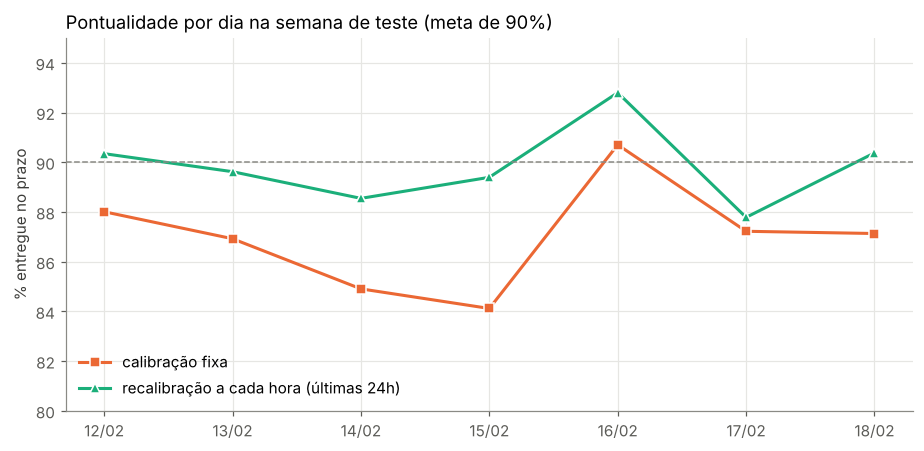

,12/02,13/02,14/02,15/02,16/02,17/02,18/02
fixo,88.0,86.9,84.9,84.1,90.7,87.2,87.1
online 24h,90.3,89.6,88.5,89.4,92.8,87.8,90.4


In [9]:
dias = df.loc[te, "created_at"].dt.strftime("%d/%m").to_numpy()
diario = pd.DataFrame({
    "fixo": pd.Series(y[te] <= pq[te] + fixo).groupby(dias).mean() * 100,
    "online 24h": pd.Series(y[te] <= pq[te] + aj24[te]).groupby(dias).mean() * 100,
})
fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(diario))
ax.plot(x, diario["fixo"], color=CORES[1], marker="s", markeredgecolor="white", label="calibração fixa")
ax.plot(x, diario["online 24h"], color=CORES[2], marker="^", markeredgecolor="white", label="recalibração a cada hora (últimas 24h)")
ax.axhline(90, color="#8a8a85", lw=1, ls="--")
ax.set_xticks(x, diario.index); ax.set_ylim(80, 95)
ax.set_ylabel("% entregue no prazo"); ax.set_title("Pontualidade por dia na semana de teste (meta de 90%)", loc="left")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.savefig("../results/recalibracao_online.png", dpi=150); plt.show()
diario.round(1).T

## Conclusão

Com recalibração online e meta de 90% (semana de teste, 50.210 entregas):

| | Regra | LightGBM mediana | **LightGBM quantílico + conformal** |
|---|---|---|---|
| Pontualidade | 88,7% | 89,8% | **89,8%** |
| Prazo médio prometido | 69,8 min | 65,9 min | **66,4 min** |
| Atraso de mais de 10 min | 5,6% | 4,4% | **4,1%** |
| Pontualidade na pior faixa de pedidos | 70,6% | 86,5% | **89,1%** |

- **O ML reduz o prazo prometido:** o app promete ~3,5 minutos a menos que a regra, com pontualidade maior e menos atrasos longos.
- **A margem variável distribui melhor o risco:** com o quantílico + conformal, todo tipo de pedido tem ~90% de chance de chegar no prazo. Com a regra, os pedidos longos chegam no prazo só 70% das vezes.
- **Recalibrar a cada hora segura a meta em dias atípicos**, como o Dia dos Namorados e o feriado, sem precisar retreinar o modelo.